C:\Users\User\AppData\Local\Temp\ipykernel_26964\1794486482.py:32: UserWarning: The CUDA compiler succeeded, but said the following:
kernel.cu

  mandelbrot_kernel = SourceModule("""


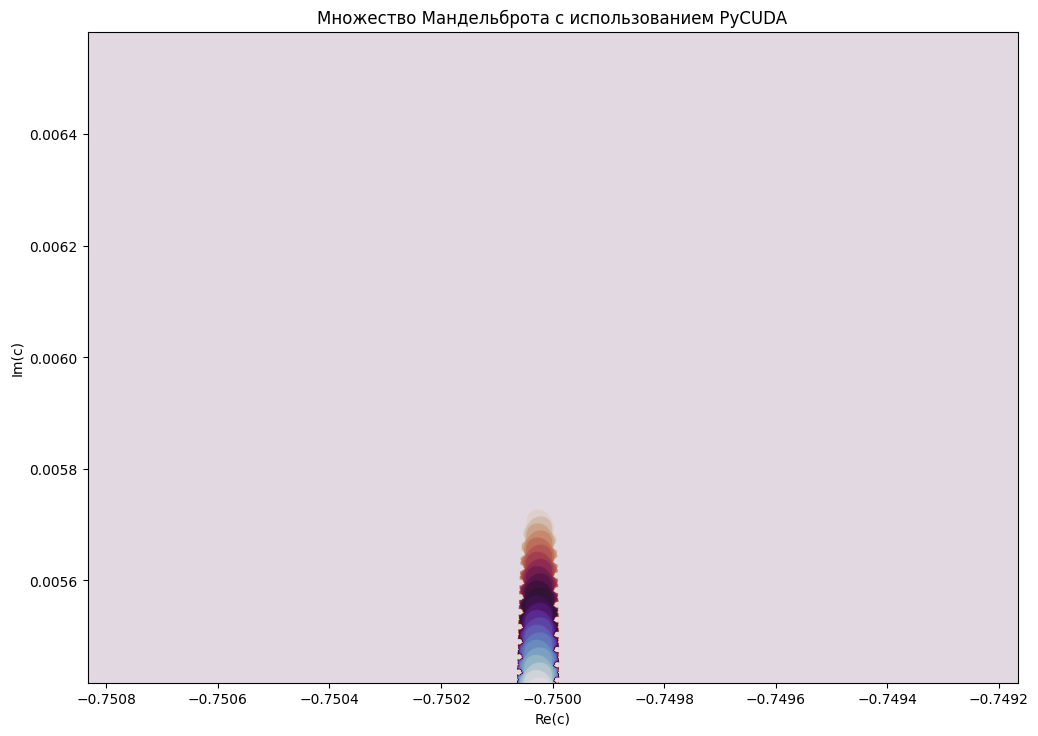

In [ ]:
# @title Множество Мандельброта 
import numpy as np
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule

# Параметры изображения
# @markdown Параметры изображения:
width = 3840 # @param {type: "integer"}
height = 2160 # @param {type: "integer"}
# @markdown Кол-во итераций для остановки проверки:
max_iter = 500 # @param {type: "integer"}

# Границы на комплексной плоскости
# Коэффициент масштабирования (scale: 1.0 - исходный масштаб, < 1.0 - приближение, > 1.0 - отдаление)
# @markdown Коэффициент масштабирования:
scale = 300 # @param {type:"number",title="12"} #2  #Adjust this value to change the zoom level
# Исходные координаты (можете менять, чтобы смотреть разные части множества)
# @markdown Исходные координаты:
center_x = -0.75 #  @param {type:"number"}
center_y =  0.006 # @param {type: "number"}
zoomed_width, zoomed_height = 0.25, 0.175  # Initial width and height for the zoomed area

# Вычисляем новые координаты на основе scale
xmin, xmax = center_x - zoomed_width / scale, center_x + zoomed_width / scale
ymin, ymax = center_y - zoomed_height / scale, center_y + zoomed_height / scale
# Преобразуем в массивы numpy для передачи на GPU
image = np.zeros((height, width), dtype=np.float32)

# CUDA-код для вычисления множества Мандельброта
mandelbrot_kernel = SourceModule("""
__global__ void mandelbrot(float *image, int width, int height, 
                           float xmin, float xmax, float ymin, float ymax, int max_iter) {
    int x = blockIdx.x * blockDim.x + threadIdx.x;
    int y = blockIdx.y * blockDim.y + threadIdx.y;

    if (x >= width || y >= height) return;

    float real = xmin + x * (xmax - xmin) / width;
    float imag = ymin + y * (ymax - ymin) / height;
    float c_real = real;
    float c_imag = imag;

    int value = 0;
    for (int i = 0; i < max_iter; i++) {
        value = i;
        float real2 = real * real;
        float imag2 = imag * imag;
        if (real2 + imag2 > 4.0f) {
            value = i;
            break;
        }
        imag = 2 * real * imag + c_imag;
        real = real2 - imag2 + c_real;
    }
    image[y * width + x] = (float)value;
}
""")

# Получаем функцию из модуля
mandelbrot = mandelbrot_kernel.get_function("mandelbrot")

# Выделяем память на GPU для изображения
image_gpu = cuda.mem_alloc(image.nbytes)



# Задаём параметры сетки и блоков
block_dim = (16, 16, 1)  # Блоки 16x16
grid_dim = ((width + block_dim[0] - 1) // block_dim[0],
            (height + block_dim[1] - 1) // block_dim[1])

# Запускаем вычисление на GPU
mandelbrot(image_gpu, np.int32(width), np.int32(height),
           np.float32(xmin), np.float32(xmax), np.float32(ymin), np.float32(ymax), 
           np.int32(max_iter), block=block_dim, grid=grid_dim)

# Копируем результат с GPU на CPU
cuda.memcpy_dtoh(image, image_gpu)

# После завершения работы с памятью, освобождение
image_gpu.free()

# Дополнительно можно вызвать сборщик мусора
import gc
gc.collect()

# Устанавливаем размер фигуры (в дюймах) для хорошего качества
fig = plt.figure(figsize=(12, 12))  # Больший размер для лучшего качества
# Отображение изображения
plt.imshow(image, extent=(xmin, xmax, ymin, ymax), cmap="twilight")
#plt.colorbar(label="Итерации до выхода за пределы")
plt.title("Множество Мандельброта с использованием PyCUDA")
plt.xlabel("Re(c)")
plt.ylabel("Im(c)")

# Сохранение изображения в формате PNG с высоким качеством
#plt.savefig("mandelbrot_set_high_quality.png", dpi=600, bbox_inches="tight", format="png")

plt.show()